# HumanAct12 데이터 살펴보기

위치: `HumanML3D/pose_data/humanact12/humanact12`. 클립 1개가 `.npy` 파일 1개로 저장되어 있다.

HumanAct12는 사람의 동작 3D 모션에 **동작 범주(12개)** 를 붙인 데이터셋이다. Action2Motion 논문에서 공개되었고, 편광 카메라로 찍은 PHSPD 데이터를 가공해 만들었다. HumanML3D의 원본 두 개 중 하나다.

AMASS와 달리 인체 모델 파라미터가 아니라 **관절 위치**가 바로 저장되어 있다.


## 1. 파일 수와 형태

`T`는 프레임 수이고 파일마다 다르다.

In [1]:
# 폴더를 다루는 라이브러리
import os
# 파일 이름을 나누는 라이브러리
import re
# .npy 파일을 읽는 라이브러리
import numpy as np
# 표를 만드는 라이브러리
import pandas as pd
# 그림을 그리는 라이브러리
import matplotlib.pyplot as plt

# 그림의 기본 색과 글자 크기 정하기
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'axes.edgecolor': '#b4b2a9', 'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e', 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})

# HumanAct12 폴더 경로
root = '/home/jaesik/mnt/HumanML3D/pose_data/humanact12/humanact12'
# .npy 파일 이름 목록 만들기
names = sorted(f for f in os.listdir(root) if f.endswith('.npy'))
# 모든 파일 불러오기
clips = {f: np.load(f'{root}/{f}') for f in names}

# 파일 수 출력
print(len(clips), 'clips')
# 파일별 (관절 수, 좌표 수) 종류 출력
print('shapes (joints, xyz):', sorted({c.shape[1:] for c in clips.values()}))
# 예시 파일의 형태와 자료형 출력
print(names[0], clips[names[0]].shape, clips[names[0]].dtype)
# 첫 프레임의 관절 0~2 출력
print(clips[names[0]][0, :3].round(3))

1191 clips
shapes (joints, xyz): [(24, 3)]
P01G01R01F0001T0064A0101.npy (64, 24, 3) float64
[[ 0.022 -0.316  2.616]
 [ 0.098 -0.404  2.614]
 [-0.047 -0.408  2.618]]


| 축 | 크기 | 내용 |
|---|---|---|
| 0 | T | 프레임 |
| 1 | 24 | 관절 |
| 2 | 3 | x, y, z 위치 (m) |

## 2. 파일 이름 읽기

`P01G01R01F0001T0064A0101.npy`처럼 이름에 정보가 들어 있다.

| 부분 | 예시 | 뜻 |
|---|---|---|
| `P` | 01 | 1~12번. 촬영된 사람 번호로 추정 |
| `G`, `R` | 01, 01 | 촬영 묶음과 반복 번호로 추정 (공식 정의는 확인하지 못함) |
| `F` | 0001 | 원본 영상의 시작 프레임 |
| `T` | 0064 | 원본 영상의 끝 프레임 |
| `A` | 0101 | 앞 두 자리는 동작 범주(1~12), 뒤 두 자리는 세부 범주 |


In [2]:
# 이름을 부분별로 나누는 패턴
pattern = re.compile(r'P(\d+)G(\d+)R(\d+)F(\d+)T(\d+)A(\d\d)(\d\d)')
# 파일마다 이름을 나눠 표의 행 만들기
rows = [dict(zip(['P', 'G', 'R', 'F', 'T', 'action', 'sub'], map(int, pattern.fullmatch(f[:-4]).groups())), file=f, frames=len(clips[f])) for f in names]
# 표 만들기
meta = pd.DataFrame(rows)
# 이름의 프레임 범위와 실제 프레임 수가 같은 파일 비율 출력
print('T - F + 1 == frames:', round(float((meta['T'] - meta['F'] + 1 == meta['frames']).mean()), 3))
# 앞 5행 출력
meta.head()

T - F + 1 == frames: 0.9


,P,G,R,F,T,action,sub,file,frames
0,1,1,1,1,64,1,1,P01G01R01F0001T0064A0101.npy,64
1,1,1,1,69,143,1,2,P01G01R01F0069T0143A0102.npy,75
2,1,1,1,151,190,1,3,P01G01R01F0151T0190A0103.npy,40
3,1,1,1,449,505,2,1,P01G01R01F0449T0505A0201.npy,57
4,1,1,1,718,825,3,1,P01G01R01F0718T0825A0301.npy,108


이름의 프레임 범위(`T - F + 1`)와 실제 프레임 수는 약 90%의 파일에서 같다. 나머지는 다르므로 길이는 이름이 아닌 실제 배열로 재야 한다.

## 3. 동작 범주

1191 clips, 34 subcategories


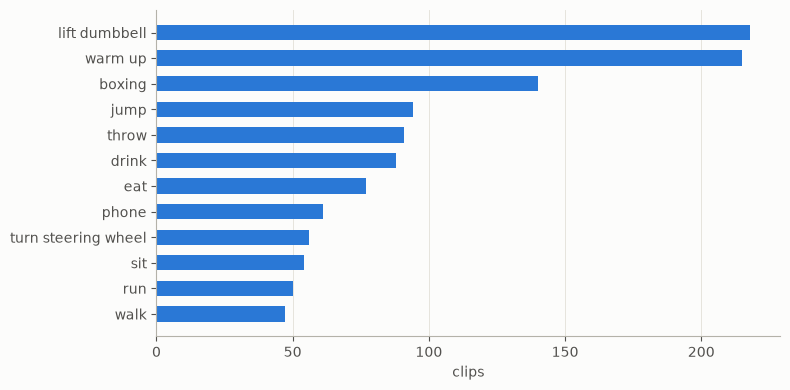

,name,clips,subcategories,median_frames
action,,,,
1,warm up,215,7,51.0
2,walk,47,1,152.0
3,run,50,1,115.0
4,jump,94,2,81.0
5,drink,88,5,69.5
6,lift dumbbell,218,5,64.5
7,sit,54,1,38.5
8,eat,77,3,58.0
9,turn steering wheel,56,1,99.0


In [3]:
# 범주 번호별 이름
action_names = {1: 'warm up', 2: 'walk', 3: 'run', 4: 'jump', 5: 'drink', 6: 'lift dumbbell', 7: 'sit', 8: 'eat', 9: 'turn steering wheel', 10: 'phone', 11: 'boxing', 12: 'throw'}
# 범주별 클립 수, 세부 범주 수, 프레임 수의 중앙값 구하기
actions = meta.groupby('action').agg(clips=('file', 'size'), subcategories=('sub', 'nunique'), median_frames=('frames', 'median'))
# 범주 이름 열을 맨 앞에 넣기
actions.insert(0, 'name', actions.index.map(action_names))
# 합계 출력
print(actions['clips'].sum(), 'clips,', actions['subcategories'].sum(), 'subcategories')

# 클립 수가 많은 순으로 정렬 (가로 막대는 아래부터 그려지므로 오름차순)
order = actions.sort_values('clips')
# 그림 1개 만들기
fig, ax = plt.subplots(figsize=(8, 4))
# 가로 막대 그리기
ax.barh(order['name'], order['clips'], color='#2a78d6', height=0.6)
# 축 이름 적기
ax.set_xlabel('clips')
# 세로 눈금선 넣기
ax.grid(axis='x', color='#e6e4dd', linewidth=0.7)
# 눈금선을 막대 뒤로 보내기
ax.set_axisbelow(True)
# 여백 맞추고 그림 출력
fig.tight_layout()
plt.show()

# 표 출력
actions

## 4. 클립 길이

파일에 프레임 속도 정보는 없다. HumanML3D는 이 데이터를 프레임을 건너뛰지 않고 20fps로 간주해 그대로 쓴다. 아래 초 단위는 20fps를 가정한 값이다.


{'count': 1191.0, 'mean': 75.6, 'std': 57.7, 'min': 8.0, '5%': 21.0, '50%': 60.0, '95%': 195.0, 'max': 470.0}


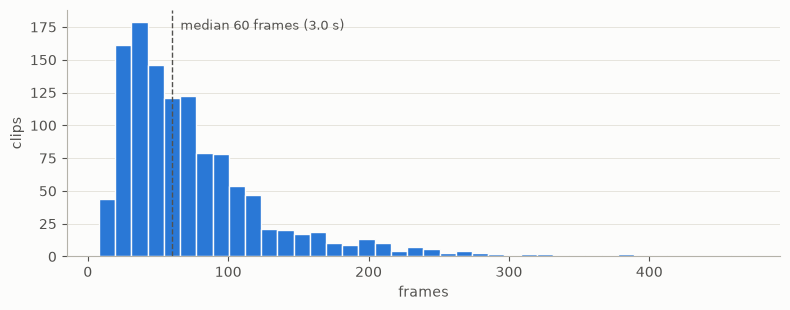

In [4]:
# 프레임 수의 분위수 출력
print(meta['frames'].describe(percentiles=[0.05, 0.5, 0.95]).round(1).to_dict())

# 그림 1개 만들기
fig, ax = plt.subplots(figsize=(8, 3.2))
# 프레임 수의 분포 그리기
ax.hist(meta['frames'], bins=40, color='#2a78d6', edgecolor='#fcfcfb', linewidth=1)
# 중앙값 위치에 세로선 긋기
ax.axvline(meta['frames'].median(), color='#52514e', linewidth=1, linestyle='--')
# 세로선 옆에 중앙값 적기
ax.annotate(f"median {meta['frames'].median():.0f} frames ({meta['frames'].median() / 20:.1f} s)", (meta['frames'].median(), ax.get_ylim()[1] * 0.92), xytext=(6, 0), textcoords='offset points', color='#52514e', fontsize=9)
# 축 이름 적기
ax.set_xlabel('frames')
ax.set_ylabel('clips')
# 가로 눈금선 넣기
ax.grid(axis='y', color='#e6e4dd', linewidth=0.7)
# 눈금선을 막대 뒤로 보내기
ax.set_axisbelow(True)
# 여백 맞추고 그림 출력
fig.tight_layout()
plt.show()

## 5. 관절과 좌표계

관절 24개는 SMPL 순서다. 0~21번은 AMASS의 몸 관절과 같은 순서이고, 22번이 왼손, 23번이 오른손이다. 손가락 관절은 없다.

좌표계를 데이터로 확인한다.


In [5]:
# 클립마다 머리(15번)와 골반(0번)의 y 차이 평균 구하기
head_up = np.array([(c[:, 15, 1] - c[:, 0, 1]).mean() for c in clips.values()])
# 클립마다 첫 프레임의 골반 위치 모으기
first_pelvis = np.stack([c[0, 0] for c in clips.values()])
# 클립마다 전체 관절의 최저 y 구하기
lowest = np.array([c[..., 1].min() for c in clips.values()])

# 머리가 골반보다 y가 큰 클립의 비율 출력
print('head above pelvis in y:', round(float((head_up > 0).mean()), 3))
# 첫 프레임 골반 위치의 평균 출력
print('first-frame pelvis mean (x, y, z):', first_pelvis.mean(axis=0).round(3))
# 클립별 최저 y의 분위수 출력
print('lowest y percentiles (5, 50, 95):', np.percentile(lowest, [5, 50, 95]).round(3))

head above pelvis in y: 1.0
first-frame pelvis mean (x, y, z): [ 0.06  -0.353  2.626]
lowest y percentiles (5, 50, 95): [-1.292 -1.205 -1.136]


y축이 위쪽이다. 다만 첫 프레임의 z가 약 2.6 m로 시작 위치가 원점이 아니고, 바닥도 y = 0이 아니다. 카메라 기준 좌표로 보이며, HumanML3D로 가공할 때 바닥과 시작 위치를 맞춘다.

## 6. 스켈레톤 그림

점프 범주의 첫 클립을 그린다. 정면에서 본 x-y 평면이다.


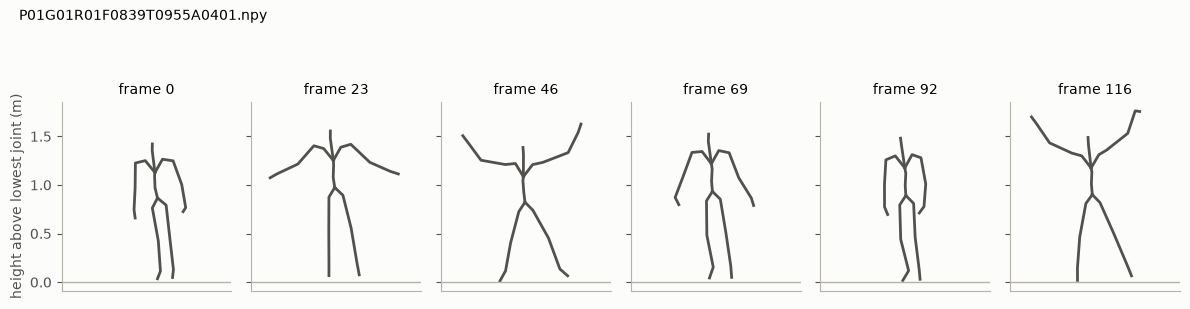

In [6]:
# 관절을 잇는 뼈대 목록 (손목에서 손까지 포함)
chains = [[0, 2, 5, 8, 11], [0, 1, 4, 7, 10], [0, 3, 6, 9, 12, 15], [9, 14, 17, 19, 21, 23], [9, 13, 16, 18, 20, 22]]
# 점프 범주의 첫 파일 고르기
sample = meta[meta['action'] == 4].iloc[0]['file']
# 그 파일의 관절 위치 꺼내기
motion = clips[sample]
# 클립 전체에서 프레임 6개 고르기
frames = np.linspace(0, len(motion) - 1, 6).astype(int)
# 클립의 최저 높이를 바닥으로 잡기
floor = motion[..., 1].min()

# 가로로 6칸 만들기
fig, axs = plt.subplots(1, 6, figsize=(12, 3.6), sharey=True)
# 칸마다 프레임 하나씩 그리기
for ax, f in zip(axs, frames):
    # 뼈대를 하나씩 그리기
    for chain in chains:
        ax.plot(motion[f, chain, 0], motion[f, chain, 1] - floor, color='#52514e', linewidth=2)
    # 바닥선 긋기
    ax.axhline(0, color='#b4b2a9', linewidth=1)
    # 프레임 번호 적기
    ax.set_title(f'frame {f}', fontsize=10)
    # 가로세로 비율을 같게 맞추기
    ax.set_aspect('equal')
    # 가로 범위를 고정하기
    ax.set_xlim(motion[..., 0].min() - 0.1, motion[..., 0].max() + 0.1)
    # 눈금 숨기기
    ax.set_xticks([])
# 왼쪽 칸에 세로축 이름 적기
axs[0].set_ylabel('height above lowest joint (m)')
# 제목에 파일 이름 적기
fig.suptitle(sample, fontsize=10, x=0.02, ha='left')
# 여백 맞추고 그림 출력
fig.tight_layout()
plt.show()

## 7. HumanML3D와의 연결

`index.csv`에서 `humanact12`가 경로에 들어간 행이 HumanAct12 클립이다. AMASS와 달리 구간을 자르지 않고 전체를 쓰므로 `end_frame`은 -1이다. 관절은 앞 22개만 쓴다.


In [7]:
# 원본과 클립의 대응표 읽기
index = pd.read_csv('/home/jaesik/mnt/HumanML3D/index.csv')
# HumanAct12 행만 고르기
linked = index[index['source_path'].str.contains('humanact12')]
# HumanAct12 클립 수와 전체 클립 수 출력
print(len(linked), 'of', len(index), 'clips come from HumanAct12')

# 첫 번째 행 꺼내기
row = linked.iloc[0]
# 원본 경로와 새 이름 출력
print(row['source_path'], '->', row['new_name'])
# 원본 관절 위치 꺼내기
raw = clips[os.path.basename(row['source_path'])]
# 가공된 관절 위치 불러오기
processed = np.load(f"/home/jaesik/mnt/HumanML3D/HumanML3D/new_joints/{row['new_name']}")
# 두 파일의 형태 출력
print('raw:', raw.shape, '| new_joints:', processed.shape)
# 두 파일의 첫 프레임 골반 위치 출력
print('first pelvis raw:', raw[0, 0].round(3), '| new_joints:', processed[0, 0].round(3))

# 이 클립의 문장 파일 열기
with open(f"/home/jaesik/mnt/HumanML3D/HumanML3D/texts/{row['new_name'][:-4]}.txt", encoding='utf-8') as f:
    # 문장을 한 줄씩 꺼내 # 앞의 문장만 출력
    for line in f:
        print('-', line.split('#')[0])

1191 of 14616 clips come from HumanAct12
./pose_data/humanact12/humanact12/P11G01R02F1812T1847A0402.npy -> 000001.npy
raw: (36, 24, 3) | new_joints: (35, 22, 3)
first pelvis raw: [ 0.037 -0.311  2.605] | new_joints: [0.    0.984 0.   ]
- a man squats extraordinarily low then bolts up in an unsatisfactory jump.
- a person falls to the ground in a sitting motion and then pops back up in a standing position.
- a person squats down then jumps
- a descends into a falling motion and thens bounces back up.


## 8. AMASS와 비교

| 항목 | AMASS | HumanAct12 |
|---|---|---|
| HumanML3D에 들어간 클립 | 13,425 | 1,191 |
| 저장 내용 | SMPL+H 파라미터 | 관절 위치 |
| 관절 수 | 52 (몸 22 + 손가락 30) | 24 |
| 라벨 | 없음 | 12개 범주, 34개 세부 범주 |
| 프레임 속도 | 파일마다 다름 (60~250fps) | 파일에 없음, 20fps로 간주 |
| 위쪽 축 | z | y |
| 관절 위치를 얻는 방법 | 인체 모델로 계산 | 그대로 사용 |
